In [1]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_data, get_column_types, TARGET, RISK_ORDER, EXPECTED_CATEGORIES
from src.eda import audit_data

In [2]:
# load + structure
df = load_data()
numeric_cols, categorical_cols = get_column_types(df)
print(df.shape)
print(df.dtypes)
df.head()

(2000, 17)
Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [3]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [4]:
print(df.isna().sum())

print("\nDuplicates:", df.duplicated().sum())

for col in EXPECTED_CATEGORIES:
    actual = set(df[col].dropna())
    expected = set(EXPECTED_CATEGORIES[col])
    print("\n", col, ":", actual - expected)

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

Duplicates: 0

 Gender : set()

 Physical_Activity : set()

 Part_Time_Job : set()

 Diet_Quality : set()

 Previous_Mental_Health_History : set()

 Mental_Health_Risk : set()


In [5]:
print("Screen_Time < Social_Media:", (df["Screen_Time_Hours"] < df["Social_Media_Hours"]).sum())

Screen_Time < Social_Media: 37


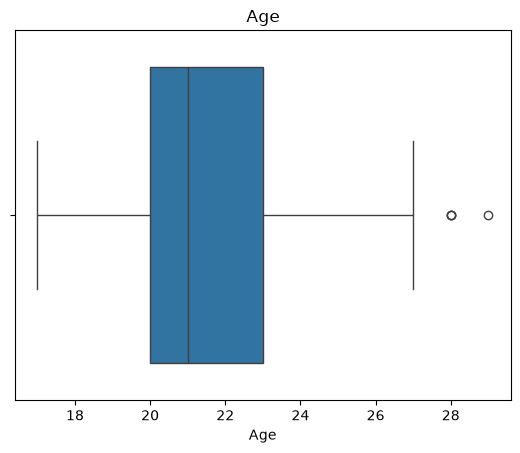

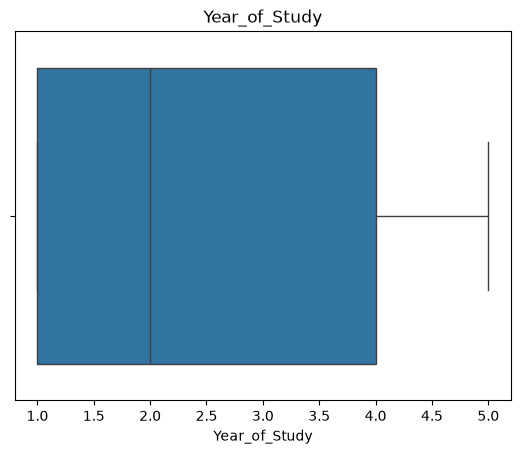

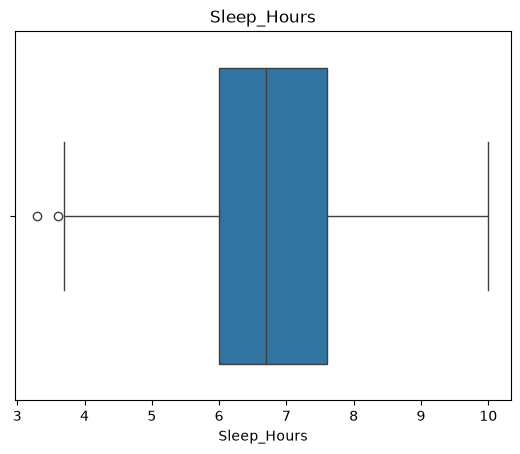

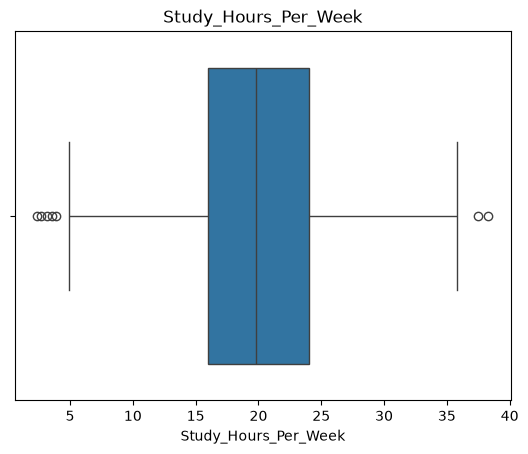

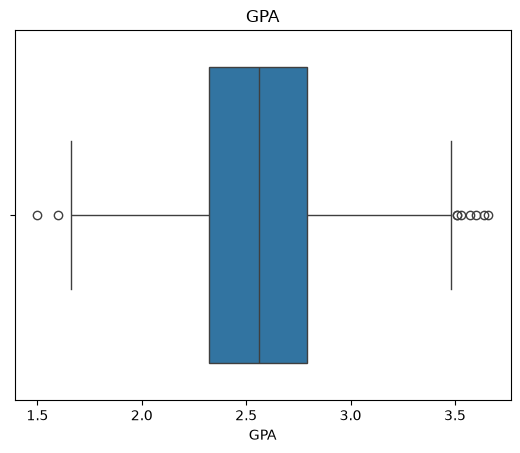

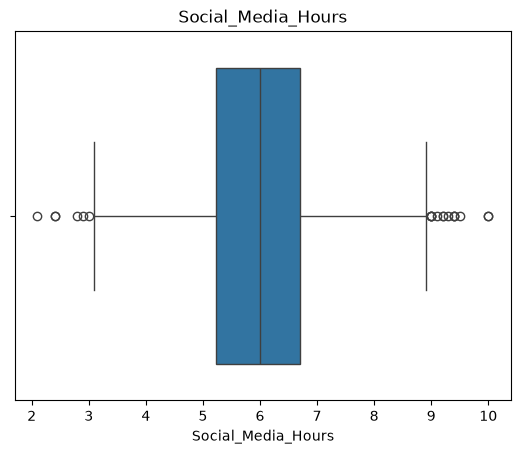

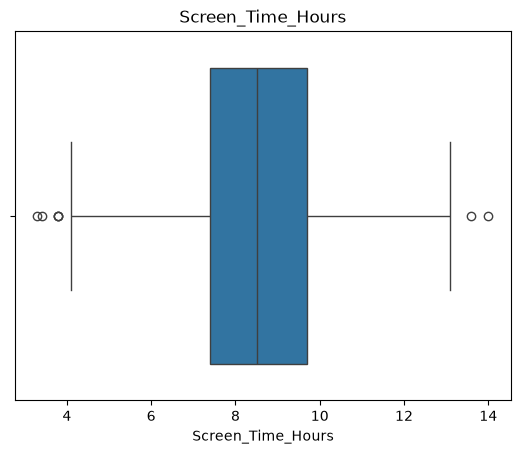

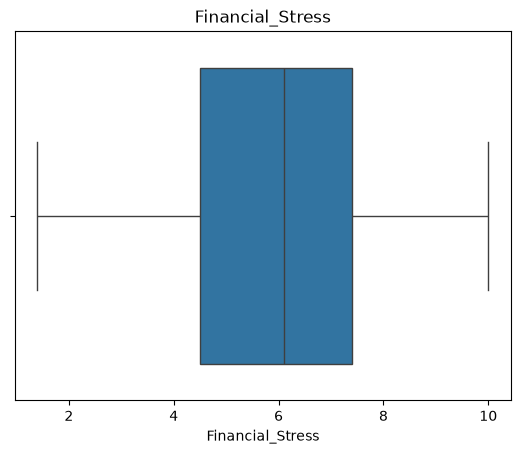

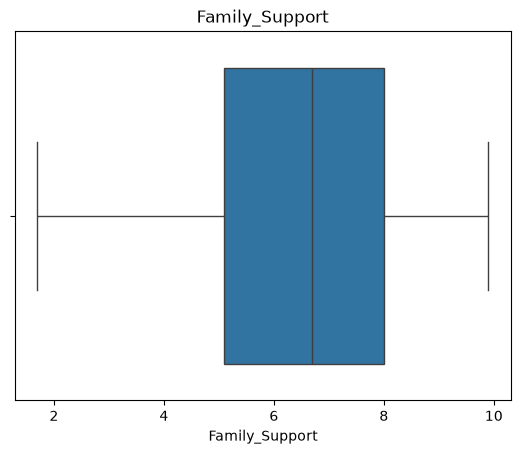

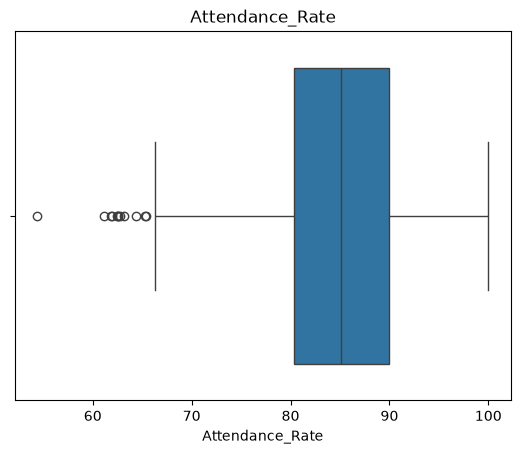

In [6]:
# outliers (IQR)
for col in numeric_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

Mental_Health_Risk
Low       660
Medium    660
High      680
Name: count, dtype: int64
Imbalance ratio: 1.03


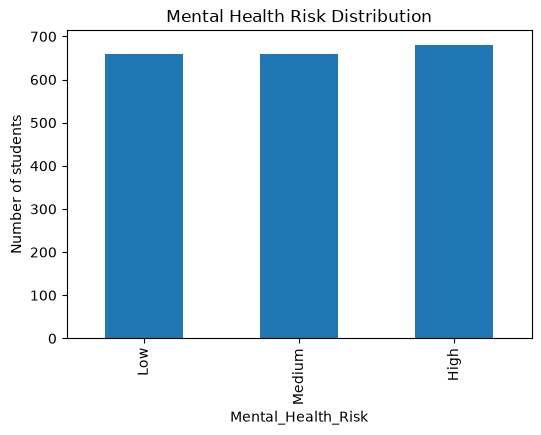

In [7]:
# target
counts = df[TARGET].value_counts().reindex(RISK_ORDER, fill_value=0)
ratio = counts.max() / counts[counts > 0].min()
print(counts)
print("Imbalance ratio:", round(ratio, 2))
counts.plot.bar(figsize=(6, 4))
plt.title("Mental Health Risk Distribution")
plt.ylabel("Number of students")
plt.show()

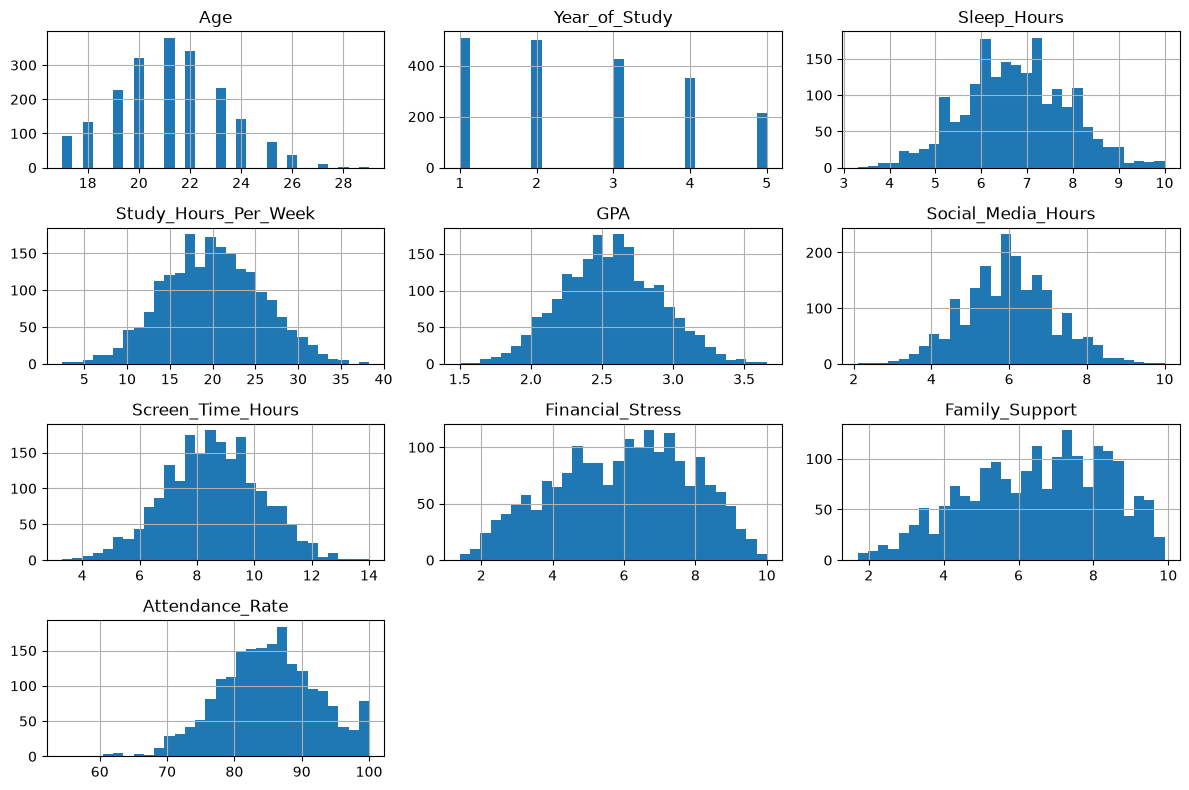

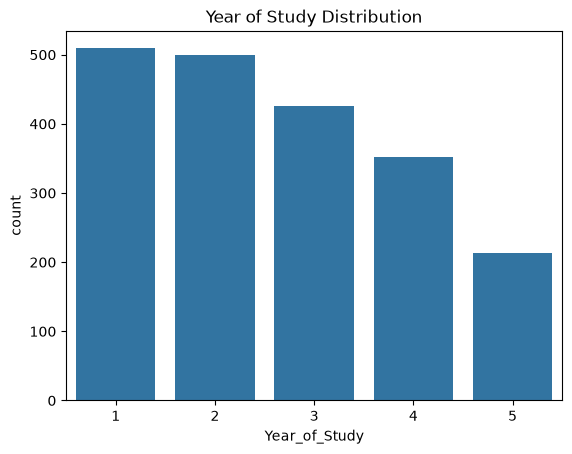

In [8]:
# features
df[numeric_cols].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

sns.countplot(data=df, x="Year_of_Study")
plt.title("Year of Study Distribution")
plt.show()

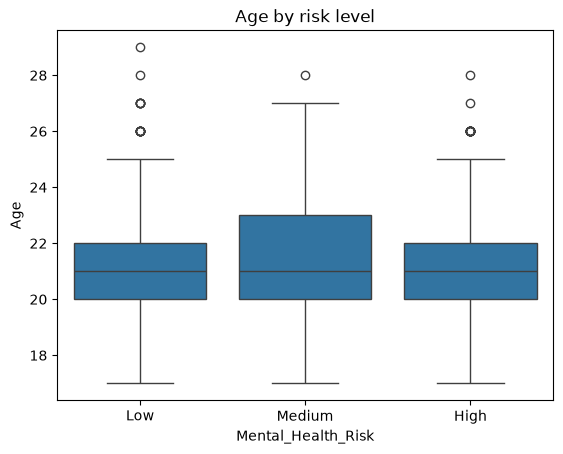

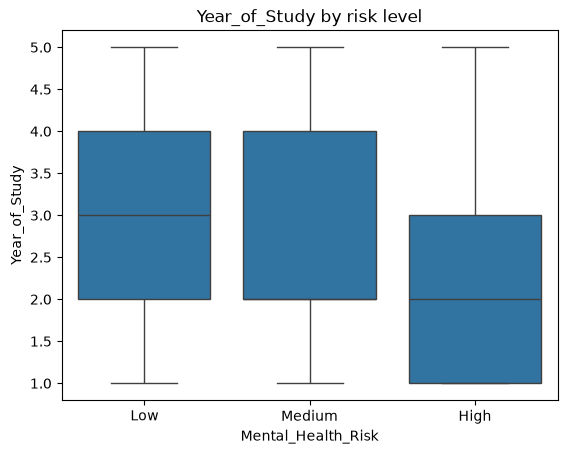

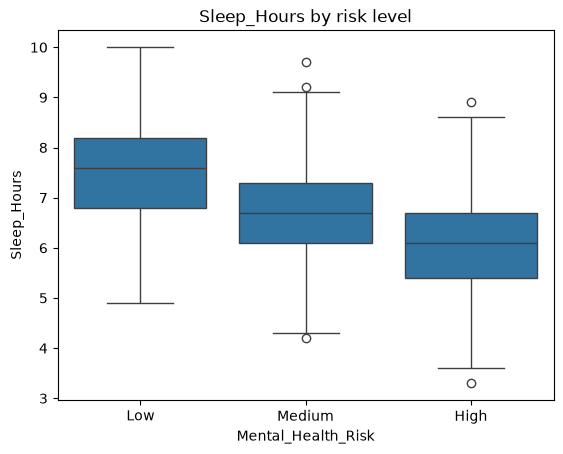

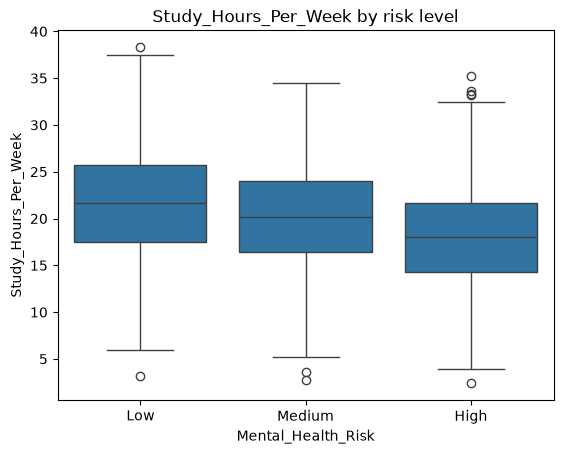

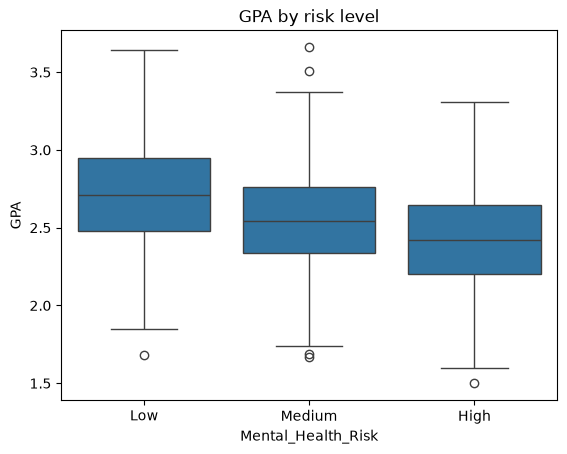

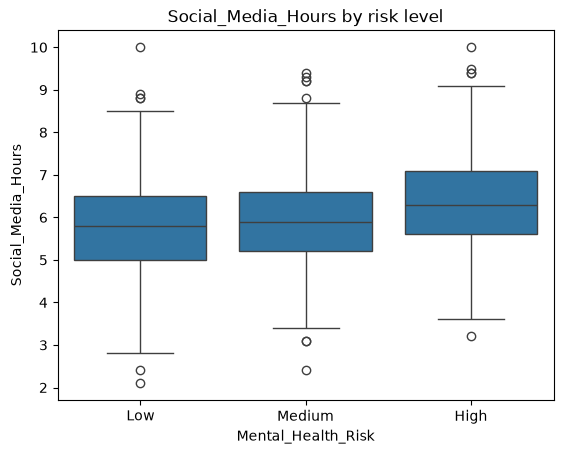

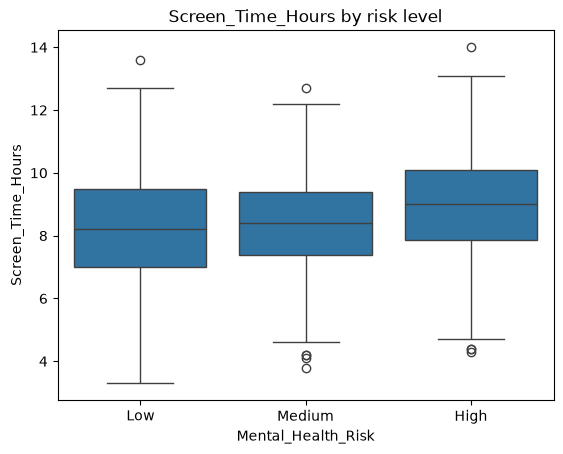

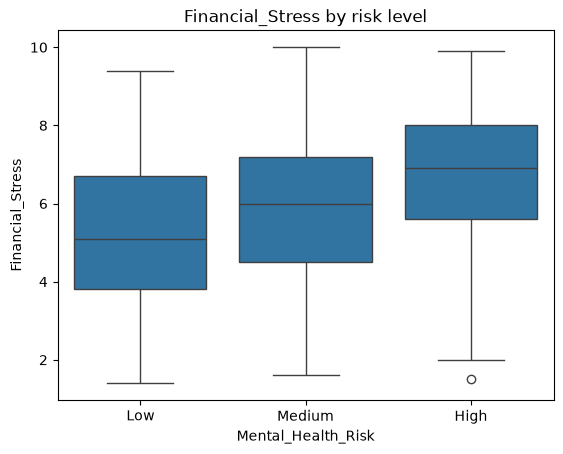

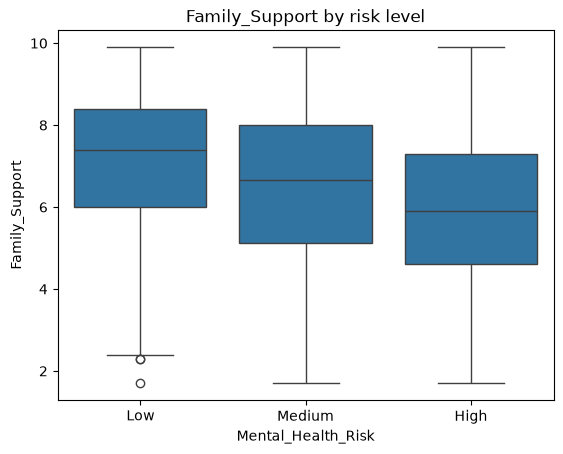

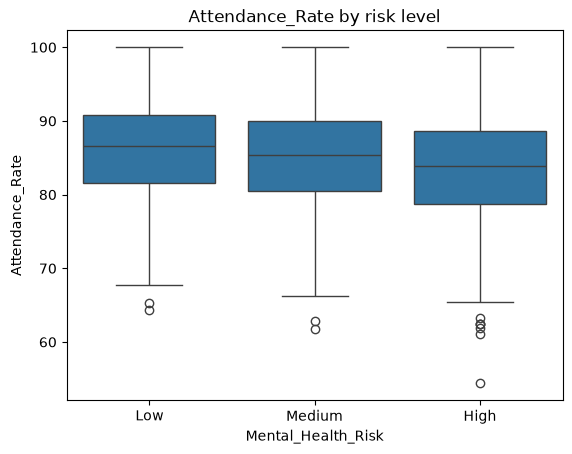

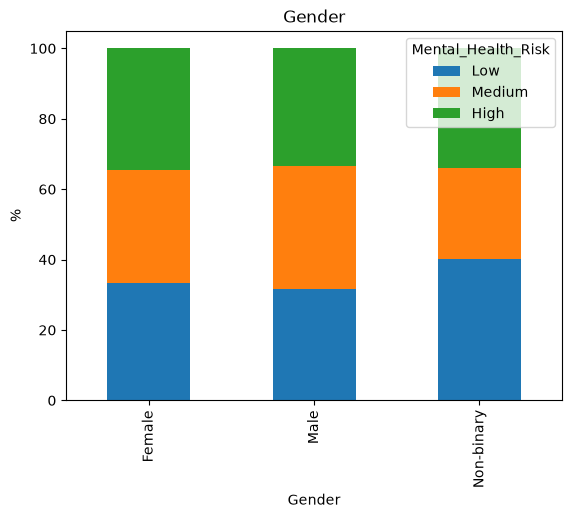

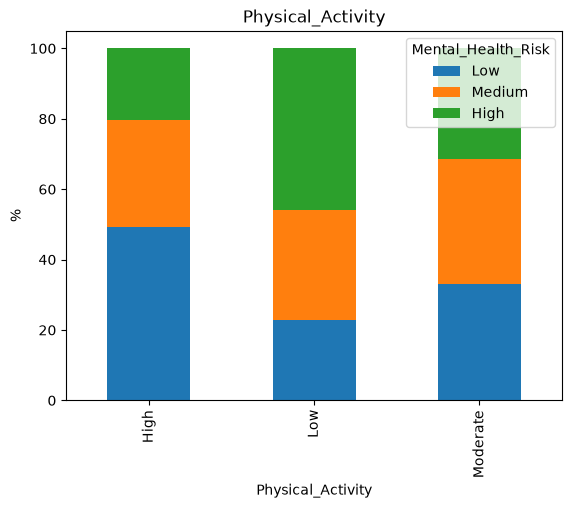

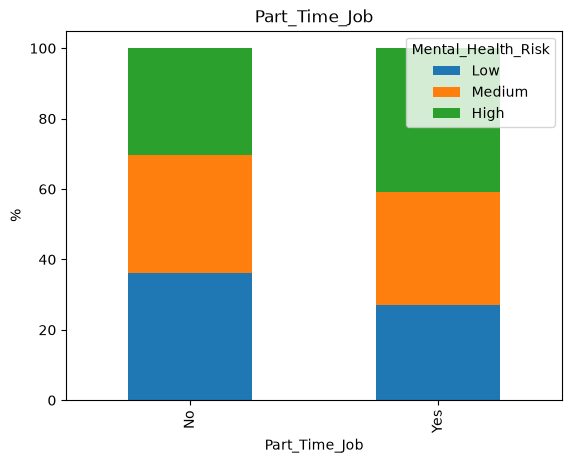

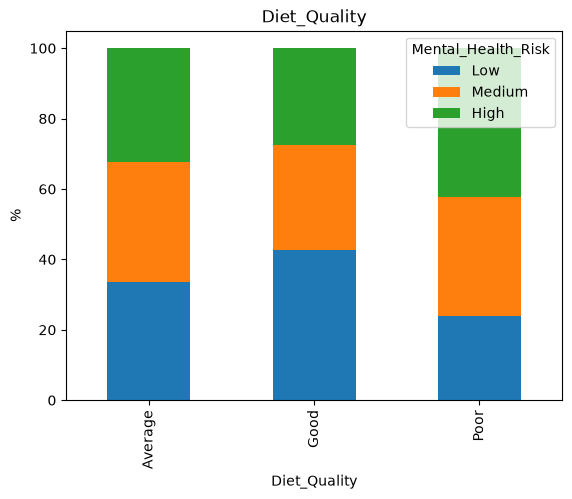

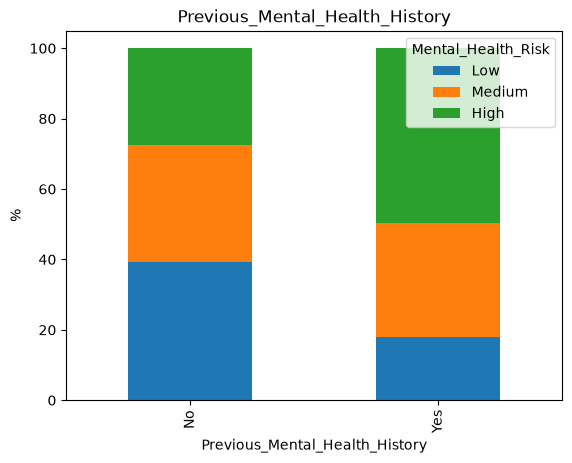

In [9]:
# features vs target
for col in numeric_cols:
    sns.boxplot(data=df, x=TARGET, y=col, order=RISK_ORDER)
    plt.title(f"{col} by risk level")
    plt.show()

for col in categorical_cols:
    table = pd.crosstab(df[col], df[TARGET], normalize="index") * 100
    table.reindex(columns=RISK_ORDER, fill_value=0).plot.bar(stacked=True)
    plt.title(col)
    plt.ylabel("%")
    plt.show()

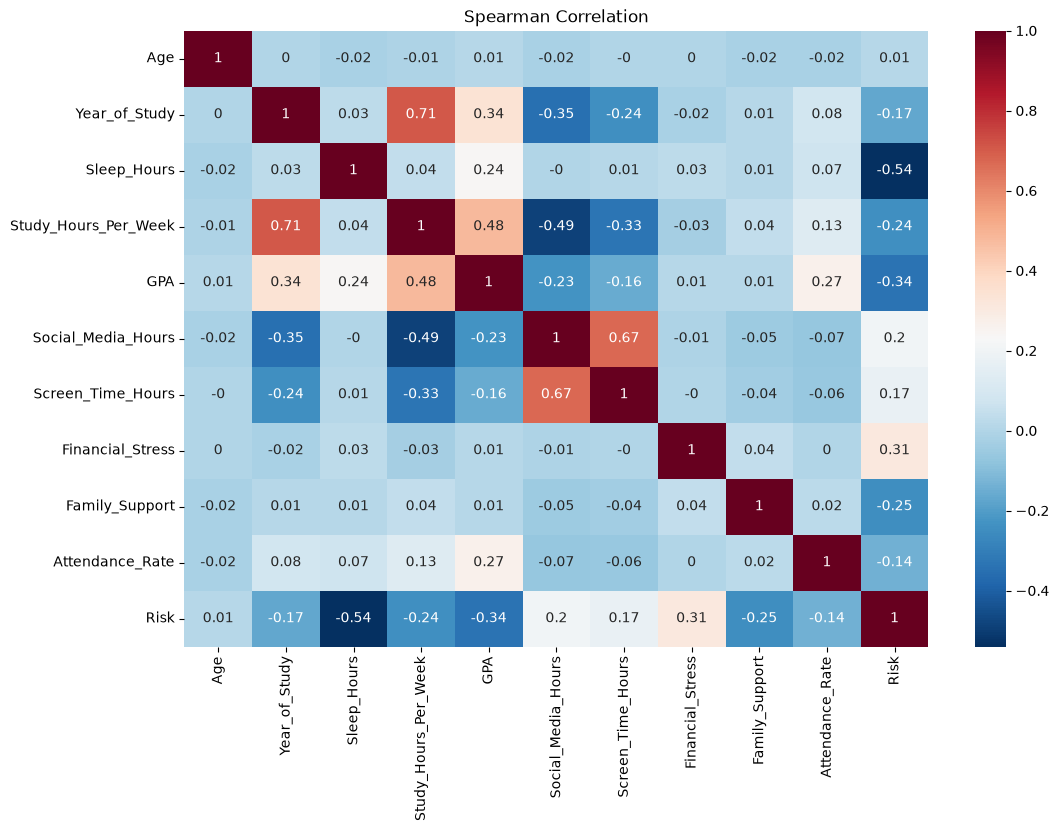

In [10]:
# correlation
risk = df[TARGET].map({"Low": 0, "Medium": 1, "High": 2})

data = df[numeric_cols].copy()
data["Risk"] = risk
plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(method="spearman").round(2), annot=True, cmap="RdBu_r")
plt.title("Spearman Correlation")
plt.show()